# Test: paw and wheel states together in the trial stacks

The trial stacks of `figure_generation/fig_segmentation` (panel i: consecutive trials of a session in real time, aligned to the go cue, one row per trial, the paw state per frame, trial events marked), now with the wheel movement state (`K_WHEEL = 8`) in the same row. Visual options only, nothing is saved:

- **A, split row**: the top half of each trial row is the paw state, the bottom half the wheel state.
- **B, stripes**: diagonal stripes alternating the paw colour and the wheel colour, every frame.
- **C, stripes while the wheel moves**: the paw colour alone while the wheel is still, stripes only during wheel movements (so stillness reads as the paw figure did, and wheel movements stand out).
- **D, one colour per joint state**: paw × whisk × lick × wheel (8 × 2 × 2 × 8 = 256) as one categorical palette with no meaning (colorcet's glasbey, the most frequent states getting the first, most distinct colours).
- **E, A with whisking and licking rows**: each trial a small block of four rows (wheel, paw, whisking, licking), with a gap between trials.

Whisking / licking (the hatching of the original stacks) are left out here so the paw + wheel encoding can be judged on its own. Same example sessions as the figure (the longest session of the 4 mice with the most trials, ≤ 5 % missing bins).

In [1]:
import sys, pathlib, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'paper-individuality' / 'paper_style.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for d in (PI, PI / 'segmentation'):
    sys.path.insert(0, str(d))
import paper_style as ps
import wheel_movement_clusters as wmc
ps.use('paper', dpi=130); ps.use_paw_states('uniform')

STATES_DIR = PI / 'data' / 'states_files_both_paws+wheelmov-sep_k8-8_own_lick-standard'
TRIALS_DIR = PI / 'data' / 'design_matrices'
SYL = sorted(glob.glob(str(PI / 'data' / 'both_paws+wheelmov-sep_k8-8_own_lick-standard_proficient_8_k_10_bin_syllables_*')))[-1]
N_EXAMPLES, MAX_MISSING, N_TRIALS, TRIAL_START = 4, 0.05, 10, 40
T_BEFORE, T_AFTER, ALIGN = 1.0, 2.5, 'goCueTrigger_times'
SUB = 8                  # pixel rows per trial (stripes need sub-row resolution)
STRIPE = 6               # stripe period in pixels (half paw colour, half wheel colour)
WM = wmc.load_model('proficient', 21)
WHEEL_COLORS = ['#ECECEC'] + wmc.colours(WM, 'small_side_vigor')[1:]
WHEEL_NAMES = wmc.state_names(WM, 'small_side_vigor')
PAW_RGB = np.array([to_rgb(c) for c in ps.PAW_STATE_COLORS]); WHEEL_RGB = np.array([to_rgb(c) for c in WHEEL_COLORS])
EVENTS = {'quiescence start': '#111111', 'stim on': '#060707', 'first movement': '#FCFBFC'}
FEEDBACK = {1: '#1B7F3B', -1: '#C0392B'}

seq = pd.read_parquet(SYL, columns=['mouse_name', 'sample', 'binned_sequence'])
seq['session'] = seq['sample'].str[:36]
miss = seq.groupby('session')['binned_sequence'].apply(lambda s: np.isnan(np.vstack(s.to_numpy())).mean())
n_tr = seq.groupby(['session', 'mouse_name']).size().div(4).reset_index(name='n')
EXAMPLES = list(n_tr.assign(missing=n_tr.session.map(miss)).query('missing <= @MAX_MISSING').sort_values('n', ascending=False)
                .drop_duplicates('mouse_name').head(N_EXAMPLES)[['session', 'mouse_name', 'n']].itertuples(index=False, name=None))
print(EXAMPLES)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


[('fece187f-b47f-4870-a1d6-619afe942a7d', 'CSH_ZAD_029', 1523.25), ('0f77ca5d-73c2-45bd-aa4c-4c5ed275dbde', 'NR_0027', 1186.25), ('af55d16f-0e31-4073-bdb5-26da54914aa2', 'ibl_witten_29', 1116.0), ('dc21e80d-97d7-44ca-a729-a8e3f9b14305', 'ibl_witten_26', 1101.0)]


In [2]:
def stack(session, mouse, dt=1 / 60):
    st = pd.read_parquet(STATES_DIR / f'8_states_file_{session}_{mouse}', columns=['Bin', 'most_likely_states', 'wheel_states'])
    tr = pd.read_parquet(TRIALS_DIR / f'session_trials_{session}_{mouse}').reset_index(drop=True).iloc[TRIAL_START:TRIAL_START + N_TRIALS]
    bins = st.Bin.to_numpy(float)
    paw_code = ps.paw_codes(st.most_likely_states.to_numpy(float))
    wheel = st.wheel_states.to_numpy(float)
    grid = np.arange(-T_BEFORE, T_AFTER + dt / 2, dt)
    P = np.full((len(tr), len(grid)), np.nan); W = P.copy()
    for i, (_, row) in enumerate(tr.iterrows()):
        a = row[ALIGN]
        if not np.isfinite(a): continue
        lo, hi = np.searchsorted(bins, [a - T_BEFORE, a + T_AFTER])
        idx = np.round((bins[lo:hi] - a + T_BEFORE) / dt).astype(int)
        keep = (idx >= 0) & (idx < len(grid))
        P[i, idx[keep]] = paw_code[lo:hi][keep]; W[i, idx[keep]] = wheel[lo:hi][keep]
    paw, whisk, lick = ps.decode_syllables(P, ps.N_PAW_STATES)
    stack.whisk_lick = (whisk, lick)          # for options D and E
    return paw, W, tr

def rgb(paw, wheel, variant):
    n, T = paw.shape
    img = np.ones((n * SUB, T, 3))
    pr = np.repeat(paw, SUB, axis=0); wr = np.repeat(wheel, SUB, axis=0)
    yy, xx = np.mgrid[:n * SUB, :T]
    if variant == 'A':
        use_wheel = (yy % SUB) >= SUB // 2
    else:
        use_wheel = ((xx + yy) // (STRIPE // 2)) % 2 == 1
        if variant == 'C':
            use_wheel &= wr > 0                    # still wheel: paw colour only
    ok_p, ok_w = np.isfinite(pr), np.isfinite(wr)
    pc = np.where(ok_p[..., None], PAW_RGB[np.nan_to_num(pr).astype(int)], 1.0)
    wc = np.where(ok_w[..., None], WHEEL_RGB[np.nan_to_num(wr).astype(int)], 1.0)
    return np.where(use_wheel[..., None], wc, pc)

def draw_stack(ax, session, mouse, variant, label=True):
    paw, W, tr = stack(session, mouse)
    ax.imshow(rgb(paw, W, variant), aspect='auto', interpolation='nearest', extent=[-T_BEFORE, T_AFTER, len(tr) - 0.5, -0.5])
    if variant == 'A':
        for i in range(len(tr)): ax.axhline(i + 0.5, color='white', lw=0.6)
    ax.axvline(0, color='white', lw=1.4); ax.axvline(0, color='0.1', lw=0.5, ls=(0, (3, 2)))
    for i, (_, row) in enumerate(tr.iterrows()):
        a = row[ALIGN]
        def mark(t, c):
            if np.isfinite(t) and -T_BEFORE <= t - a <= T_AFTER:
                ax.plot([t - a] * 2, [i - 0.45, i + 0.45], color=c, lw=0.8, solid_capstyle='butt')
        if np.isfinite(row.get('quiescencePeriod', np.nan)):
            mark(row['goCueTrigger_times'] - row['quiescencePeriod'], EVENTS['quiescence start'])
        mark(row.get('stimOn_times', np.nan), EVENTS['stim on'])
        mark(row.get('firstMovement_times', np.nan), EVENTS['first movement'])
        fb = row.get('feedbackType', np.nan)
        if np.isfinite(fb): mark(row.get('feedback_times', np.nan), FEEDBACK.get(int(fb), '0.4'))
    ax.set_yticks([0, len(tr) - 1]); ax.set_yticklabels([1, len(tr)])
    if label: ax.set_title(f'{mouse}', fontsize=7)

## The three options, same four sessions (rows = options)

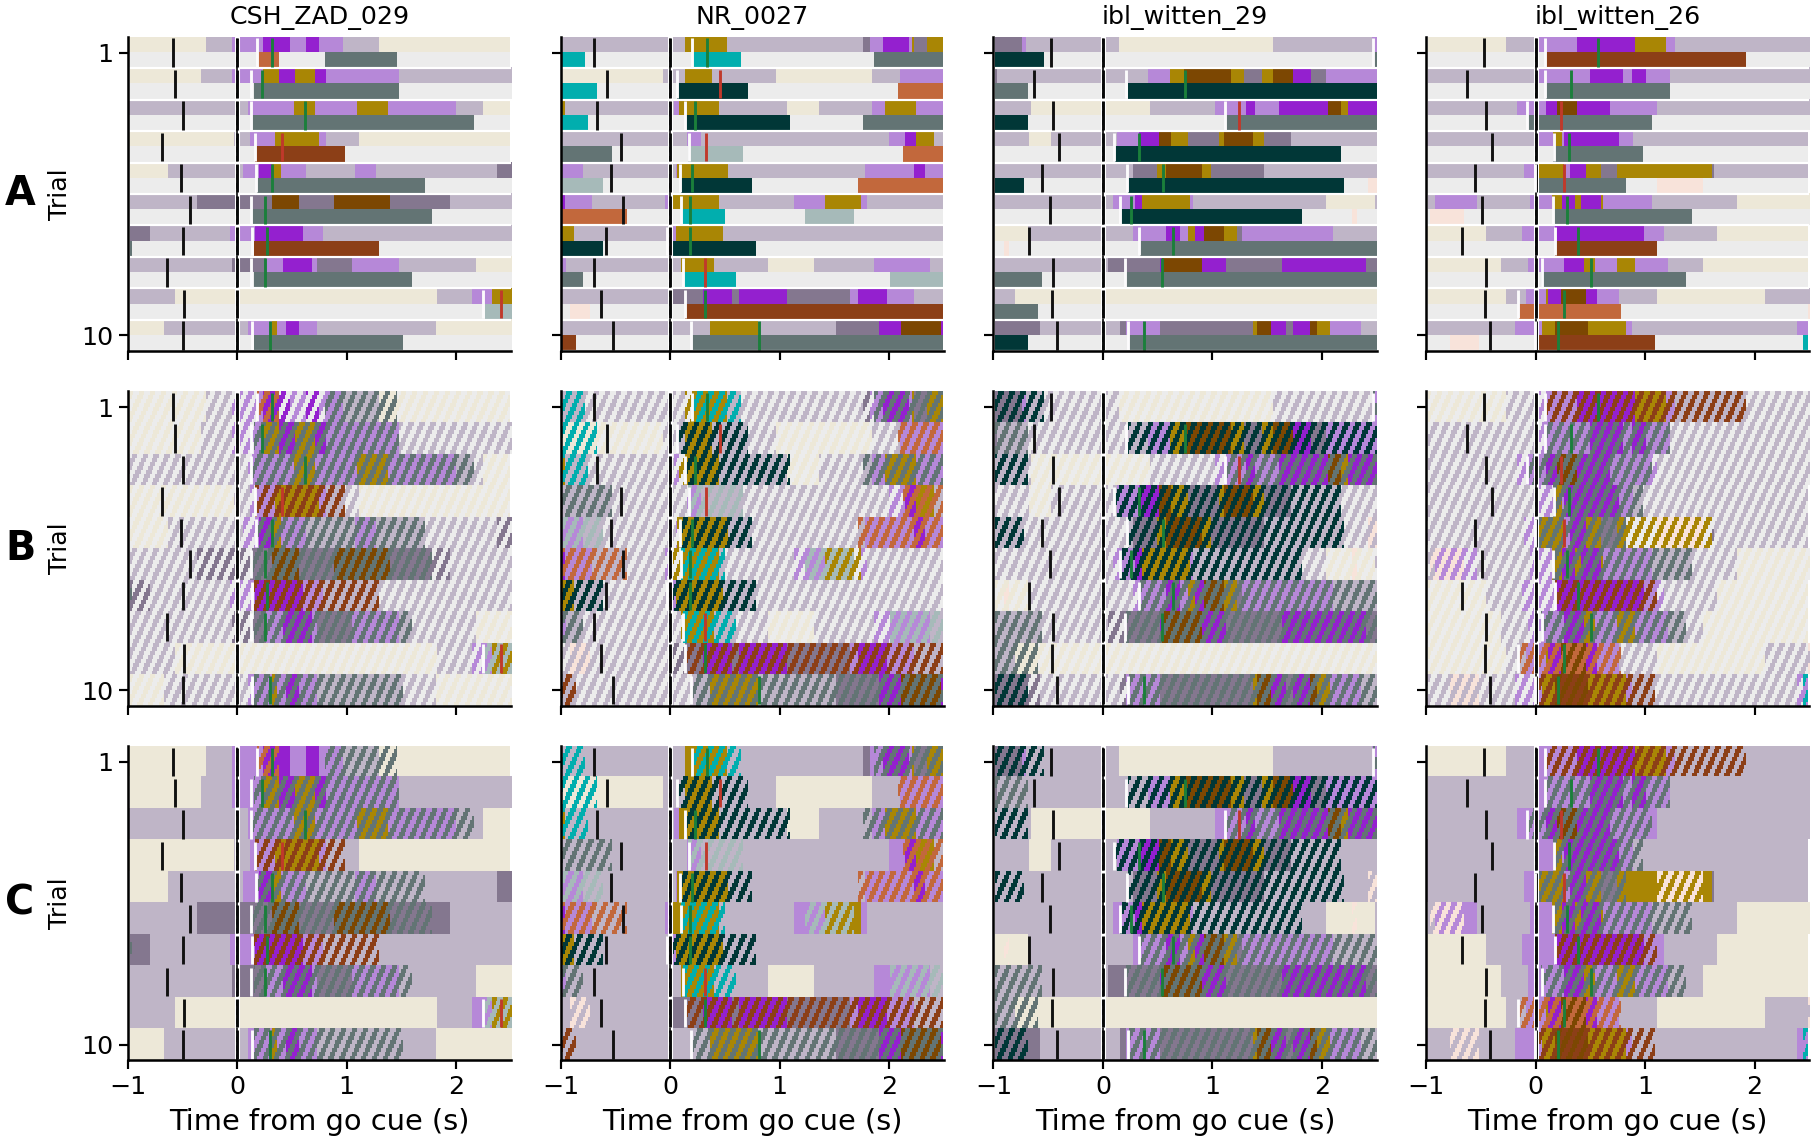

In [3]:
fig, axs = plt.subplots(3, len(EXAMPLES), figsize=(7.09, 4.6), sharex=True)
names = {'A': 'A  split row (top paw, bottom wheel)', 'B': 'B  stripes, every frame', 'C': 'C  stripes only while the wheel moves'}
for r, v in enumerate('ABC'):
    for j, (s, m, n) in enumerate(EXAMPLES):
        draw_stack(axs[r, j], s, m, v, label=(r == 0))
        if j: axs[r, j].set_yticklabels([])
    axs[r, 0].set_ylabel('Trial', fontsize=7)
    axs[r, 0].text(-0.32, 0.5, v, transform=axs[r, 0].transAxes, fontsize=11, fontweight='bold', va='center')
for ax in axs[-1]: ax.set_xlabel('Time from go cue (s)')
plt.tight_layout()

## Close-up: one session, larger

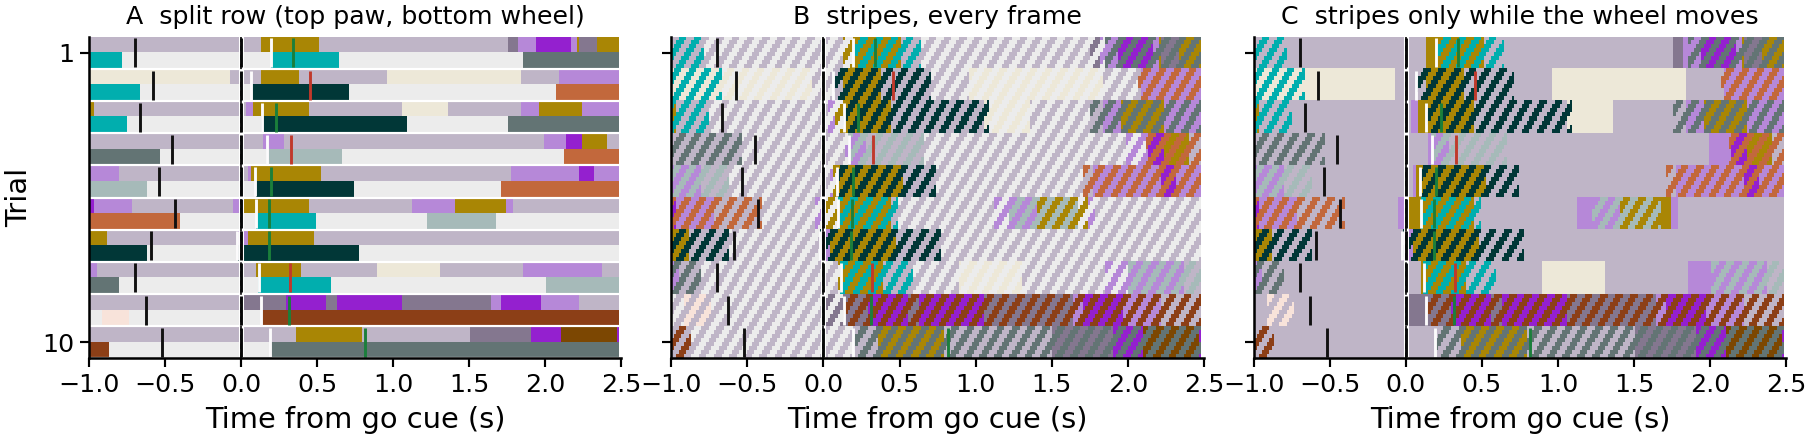

In [4]:
s, m, n = EXAMPLES[1]
fig, axs = plt.subplots(1, 3, figsize=(7.09, 1.9), sharey=True)
for ax, v in zip(axs, 'ABC'):
    draw_stack(ax, s, m, v, label=False); ax.set_title(names[v], fontsize=7); ax.set_xlabel('Time from go cue (s)')
axs[0].set_ylabel('Trial'); plt.tight_layout()

## How big is the joint space?

Paw (8) × whisking (2) × licking (2) × wheel (8) = **256** possible joint states per frame. How many are actually used: every frame of the trials of 40 random cohort sessions.

7,634,112 frames: 225 of 256 joint states occur at all; 5 cover 50%, 30 cover 80%, 53 cover 90%, 75 cover 95%, 118 cover 99%
paw x whisk x lick alone (32): 32 occur; wheel (8): 8


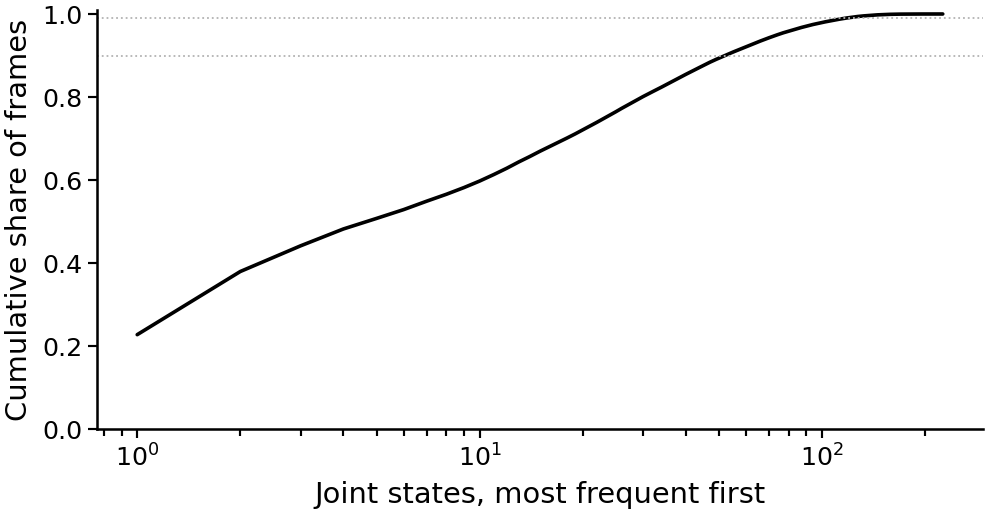

In [5]:
import os
rng = np.random.default_rng(0)
files = rng.choice(sorted(os.listdir(STATES_DIR)), 40, replace=False)
codes = []
for f in files:
    if not f.startswith('8_states_file_'): continue
    st = pd.read_parquet(STATES_DIR / f, columns=['trial_id', 'most_likely_states', 'wheel_states']).dropna()
    paw, wh, li = ps.decode_syllables(ps.paw_codes(st.most_likely_states.to_numpy(float)), ps.N_PAW_STATES)
    codes.append((paw + 8 * wh + 16 * li + 32 * st.wheel_states.to_numpy()).astype(int))
codes = np.concatenate(codes)
freq = pd.Series(codes).value_counts(normalize=True)
cum = freq.cumsum().to_numpy()
print(f'{len(codes):,} frames: {len(freq)} of 256 joint states occur at all; '
      + ', '.join(f'{int(np.searchsorted(cum, q) + 1)} cover {q:.0%}' for q in (0.5, 0.8, 0.9, 0.95, 0.99)))
print(f'paw x whisk x lick alone (32): {pd.Series(codes % 32).nunique()} occur; wheel (8): {pd.Series(codes // 32).nunique()}')
fig, ax = plt.subplots(figsize=(4, 2.2))
ax.plot(np.arange(1, len(cum) + 1), cum, color='k', lw=1)
for q in (0.9, 0.99): ax.axhline(q, color='0.7', lw=0.5, ls=':')
ax.set(xlabel='Joint states, most frequent first', ylabel='Cumulative share of frames', xscale='log', ylim=(0, 1.01)); plt.tight_layout()
RANK = {c: i for i, c in enumerate(freq.index)}       # joint code -> frequency rank (palette index)

## D: one colour per joint state (no meaning, glasbey palette by frequency rank)

Text(0.0, 1.0, 'the 64 most frequent joint states, in order')

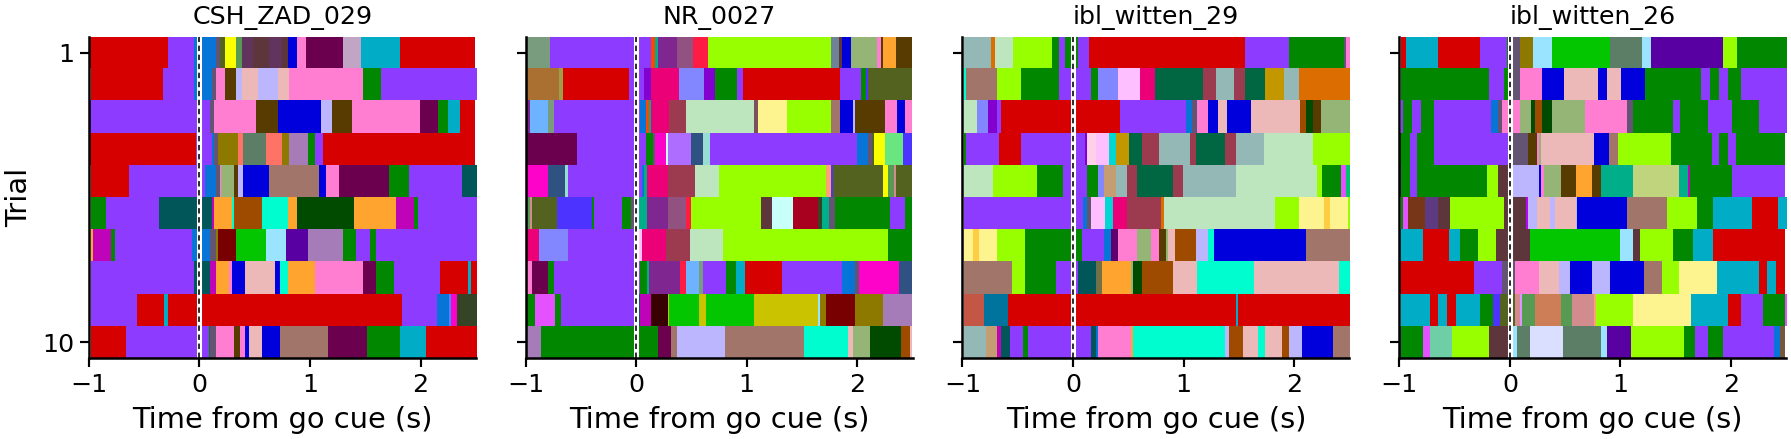

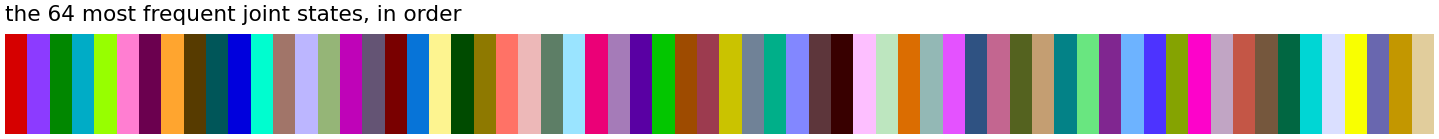

In [6]:
import colorcet
GLASBEY = np.array([to_rgb(c) for c in colorcet.glasbey])
def joint_rgb(paw, wheel, whisk, lick):
    code = paw + 8 * whisk + 16 * lick + 32 * wheel
    ok = np.isfinite(code)
    idx = np.array([RANK.get(int(c), 255) if o else 0 for c, o in zip(code.ravel(), ok.ravel())]).reshape(code.shape)
    img = GLASBEY[np.minimum(idx, 255)]
    img[~ok] = 1.0
    return img

fig, axs = plt.subplots(1, len(EXAMPLES), figsize=(7.09, 1.9), sharey=True)
for ax, (s, m, n) in zip(axs, EXAMPLES):
    paw, W, tr = stack(s, m); wh, li = stack.whisk_lick
    ax.imshow(joint_rgb(paw, W, wh, li), aspect='auto', interpolation='nearest', extent=[-T_BEFORE, T_AFTER, len(tr) - 0.5, -0.5])
    ax.axvline(0, color='white', lw=1.4); ax.axvline(0, color='0.1', lw=0.5, ls=(0, (3, 2)))
    ax.set_title(m, fontsize=7); ax.set_xlabel('Time from go cue (s)')
    ax.set_yticks([0, len(tr) - 1]); ax.set_yticklabels([1, len(tr)])
axs[0].set_ylabel('Trial'); plt.tight_layout()
fig, ax = plt.subplots(figsize=(7.09, 0.5)); ax.set_axis_off()
ax.imshow(GLASBEY[None, :64], aspect='auto', extent=[0, 64, 0, 1]); ax.set_title('the 64 most frequent joint states, in order', fontsize=6, loc='left')

## E: A with whisking and licking rows, and a gap between trials

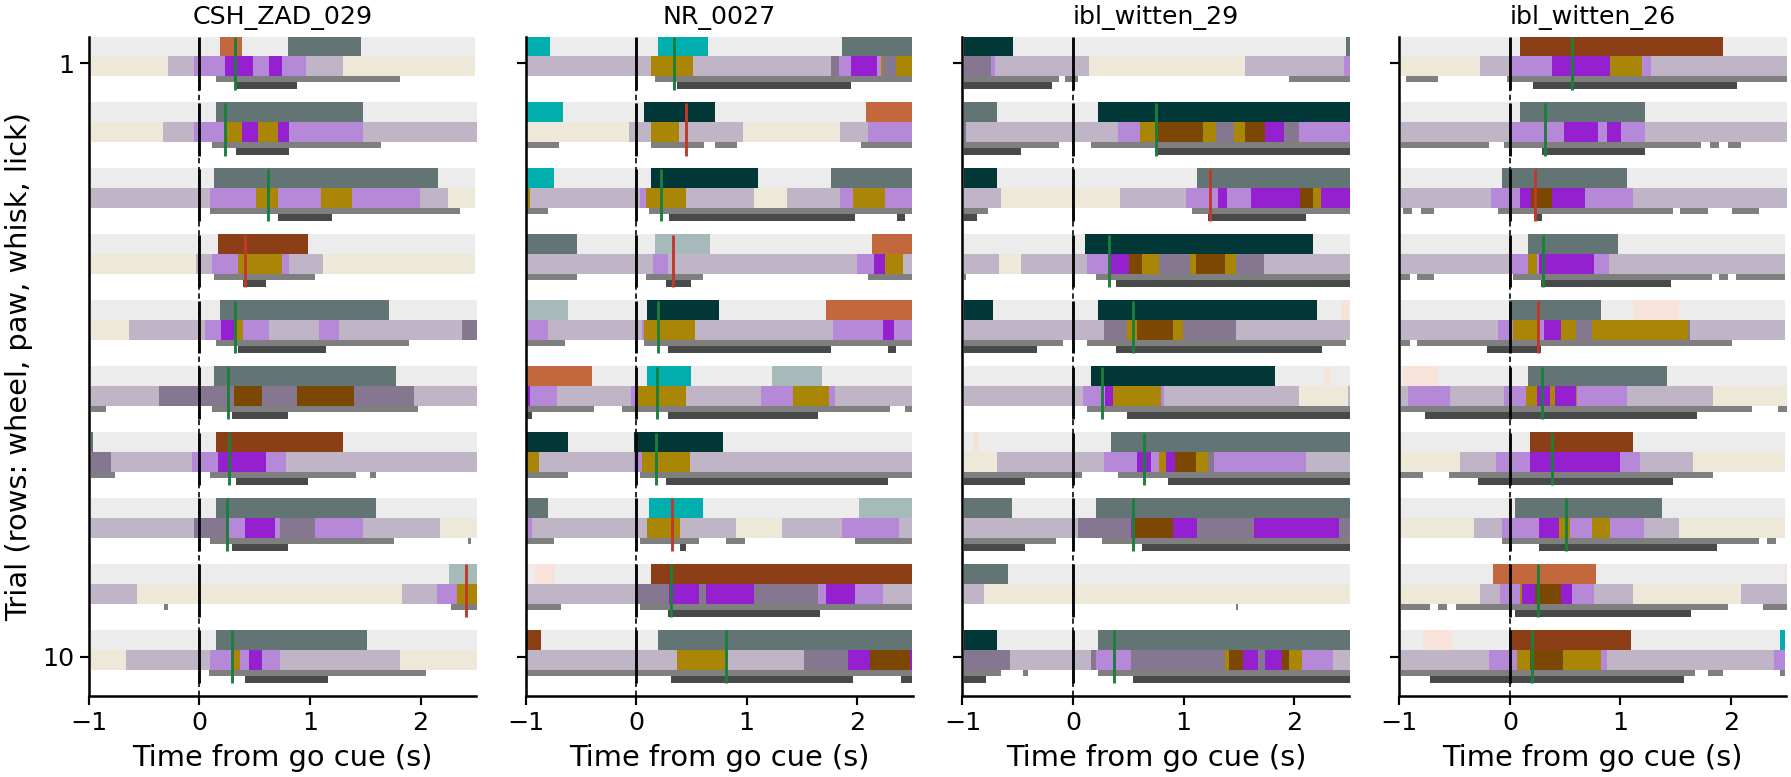

In [7]:
ROWS_E = [('wheel', 3), ('paw', 3), ('whisk', 1), ('lick', 1)]   # (channel, pixel rows); then GAP blank rows
GAP = 2
WL_RGB = {'whisk': np.array(to_rgb('#7F7F7F')), 'lick': np.array(to_rgb(ps.SYLLABLE['Lick']))}
def rgb_E(paw, wheel, whisk, lick):
    n, T = paw.shape
    blocks = []
    for i in range(n):
        for ch, h in ROWS_E:
            if ch == 'paw':
                row = np.where(np.isfinite(paw[i])[:, None], PAW_RGB[np.nan_to_num(paw[i]).astype(int)], 1.0)
            elif ch == 'wheel':
                row = np.where(np.isfinite(wheel[i])[:, None], WHEEL_RGB[np.nan_to_num(wheel[i]).astype(int)], 1.0)
            else:
                v = whisk[i] if ch == 'whisk' else lick[i]
                row = np.where((v == 1)[:, None], WL_RGB[ch], 1.0)
            blocks.append(np.repeat(row[None], h, axis=0))
        blocks.append(np.ones((GAP, T, 3)))
    return np.concatenate(blocks)
H = sum(h for _, h in ROWS_E) + GAP

def draw_E(ax, s, m):
    paw, W, tr = stack(s, m); wh, li = stack.whisk_lick
    img = rgb_E(paw, W, wh, li)
    ax.imshow(img, aspect='auto', interpolation='nearest', extent=[-T_BEFORE, T_AFTER, img.shape[0], 0])
    ax.axvline(0, color='0.1', lw=0.5, ls=(0, (3, 2)))
    for i, (_, row) in enumerate(tr.iterrows()):
        a = row[ALIGN]; y0, y1 = i * H, i * H + H - GAP
        def mark(t, c):
            if np.isfinite(t) and -T_BEFORE <= t - a <= T_AFTER:
                ax.plot([t - a] * 2, [y0, y1], color=c, lw=0.8, solid_capstyle='butt')
        mark(row.get('stimOn_times', np.nan), EVENTS['stim on'])
        fb = row.get('feedbackType', np.nan)
        if np.isfinite(fb): mark(row.get('feedback_times', np.nan), FEEDBACK.get(int(fb), '0.4'))
    ax.set_yticks([H / 2 - GAP / 2, (len(tr) - 0.5) * H - GAP / 2]); ax.set_yticklabels([1, len(tr)])
    ax.set_title(m, fontsize=7)

fig, axs = plt.subplots(1, len(EXAMPLES), figsize=(7.09, 3.2), sharey=True)
for ax, (s, m, n) in zip(axs, EXAMPLES):
    draw_E(ax, s, m); ax.set_xlabel('Time from go cue (s)')
axs[0].set_ylabel('Trial (rows: wheel, paw, whisk, lick)'); plt.tight_layout()

## F: paw in the base, wheel as stripes, whisking as grey stripes the other way, licks as dots

C extended to all four channels: paw colour everywhere; while the wheel moves, '/' stripes in the wheel colour; while whisking, thinner '\\' stripes in grey; while licking, a grid of dark dots. The image is drawn at a higher sub-row resolution (`SUB_F` pixel rows per trial) so the textures resolve.

Text(0.5, 1.0, 'NR_0027: paw = base colour, wheel = / stripes, whisking = grey \\\\ lines, licking = dots')

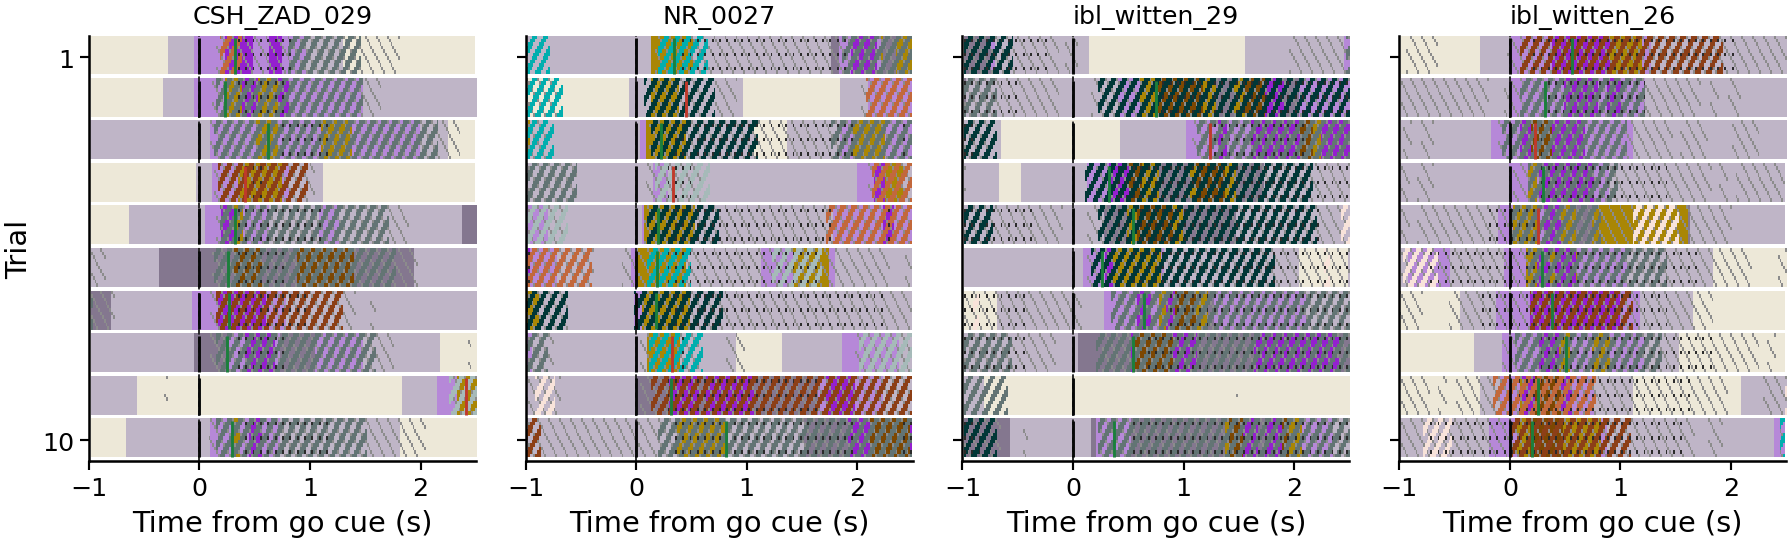

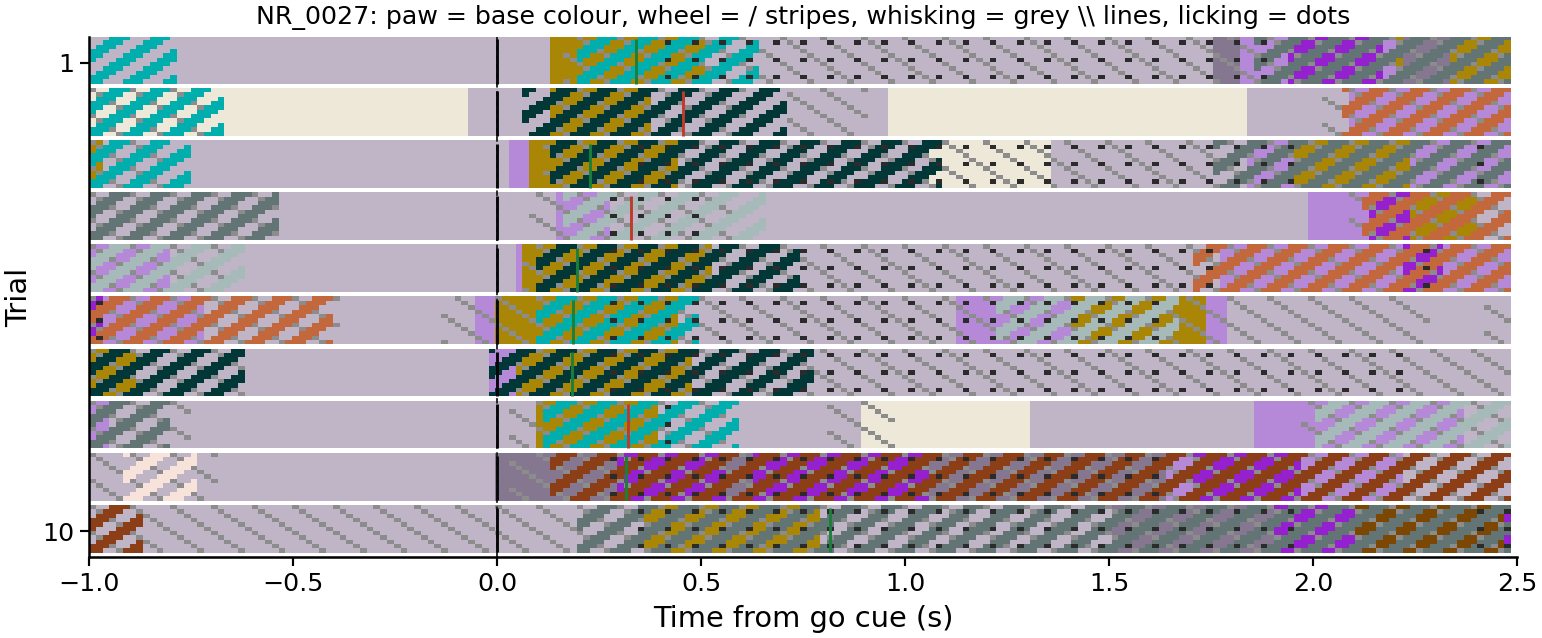

In [8]:
SUB_F, P_W, P_WH, DOT = 12, 6, 6, 4       # pixel rows per trial; wheel / whisk stripe periods; dot spacing
WHISK_GREY, LICK_DOT = np.array(to_rgb('#8C8C8C')), np.array(to_rgb('#2B2B2B'))
def rgb_F(paw, wheel, whisk, lick):
    n, T = paw.shape
    up = lambda a: np.repeat(a, SUB_F, axis=0)
    pr, wr, whr, lr = up(paw), up(wheel), up(whisk), up(lick)
    yy, xx = np.mgrid[:n * SUB_F, :T]
    img = np.where(np.isfinite(pr)[..., None], PAW_RGB[np.nan_to_num(pr).astype(int)], 1.0)
    wheel_on = (wr > 0) & (((xx + yy) // (P_W // 2)) % 2 == 1)                 # '/' stripes, half the period
    img = np.where(wheel_on[..., None], WHEEL_RGB[np.nan_to_num(wr).astype(int)], img)
    whisk_on = (whr == 1) & (((xx - yy) % P_WH) == 0) & ~wheel_on               # thin '\\' lines
    img = np.where(whisk_on[..., None], WHISK_GREY, img)
    lick_on = (lr == 1) & (xx % DOT == 1) & (yy % DOT == 1)                      # dots
    img = np.where(lick_on[..., None], LICK_DOT, img)
    img[(yy % SUB_F) == SUB_F - 1] = 1.0                                         # thin white line between trials
    return img

def draw_F(ax, s, m):
    paw, W, tr = stack(s, m); wh, li = stack.whisk_lick
    ax.imshow(rgb_F(paw, W, wh, li), aspect='auto', interpolation='nearest', extent=[-T_BEFORE, T_AFTER, len(tr) - 0.5, -0.5])
    ax.axvline(0, color='0.1', lw=0.5, ls=(0, (3, 2)))
    for i, (_, row) in enumerate(tr.iterrows()):
        a = row[ALIGN]
        def mark(t, c):
            if np.isfinite(t) and -T_BEFORE <= t - a <= T_AFTER:
                ax.plot([t - a] * 2, [i - 0.45, i + 0.4], color=c, lw=0.8, solid_capstyle='butt')
        mark(row.get('stimOn_times', np.nan), EVENTS['stim on'])
        fb = row.get('feedbackType', np.nan)
        if np.isfinite(fb): mark(row.get('feedback_times', np.nan), FEEDBACK.get(int(fb), '0.4'))
    ax.set_yticks([0, len(tr) - 1]); ax.set_yticklabels([1, len(tr)]); ax.set_title(m, fontsize=7)

fig, axs = plt.subplots(1, len(EXAMPLES), figsize=(7.09, 2.3), sharey=True)
for ax, (s, m, n) in zip(axs, EXAMPLES):
    draw_F(ax, s, m); ax.set_xlabel('Time from go cue (s)')
axs[0].set_ylabel('Trial'); plt.tight_layout()
s, m, n = EXAMPLES[1]
fig, ax = plt.subplots(figsize=(7.09, 2.6)); draw_F(ax, s, m); ax.set_xlabel('Time from go cue (s)'); ax.set_ylabel('Trial')
ax.set_title(f'{m}: paw = base colour, wheel = / stripes, whisking = grey \\\\ lines, licking = dots', fontsize=7)

## Conditional composition with time resolution: what the paw does, given what the wheel does

The time-warped syllables (10 bins per epoch, all trials of all cohort sessions). For every bin, the paw-state composition **given** the wheel state in the same bin, for five wheel conditions (still, small, left = left mid + high, balanced, right). Each panel is a stacked composition over the 40 bins, like the original all-trials composition; the black line on top is how often that wheel condition occurs in the bin (its support; bins where it covers < 1 % of trials are hatched out, their composition is noise). Read across panels at the same bin: if the paw composition differs, paw and wheel co-vary at that moment of the trial.

206,879 trials; {'Wheel still': '61.0%', 'Small': '1.0%', 'Left': '9.3%', 'Balanced': '18.0%', 'Right': '9.6%'} (mean share of bins)


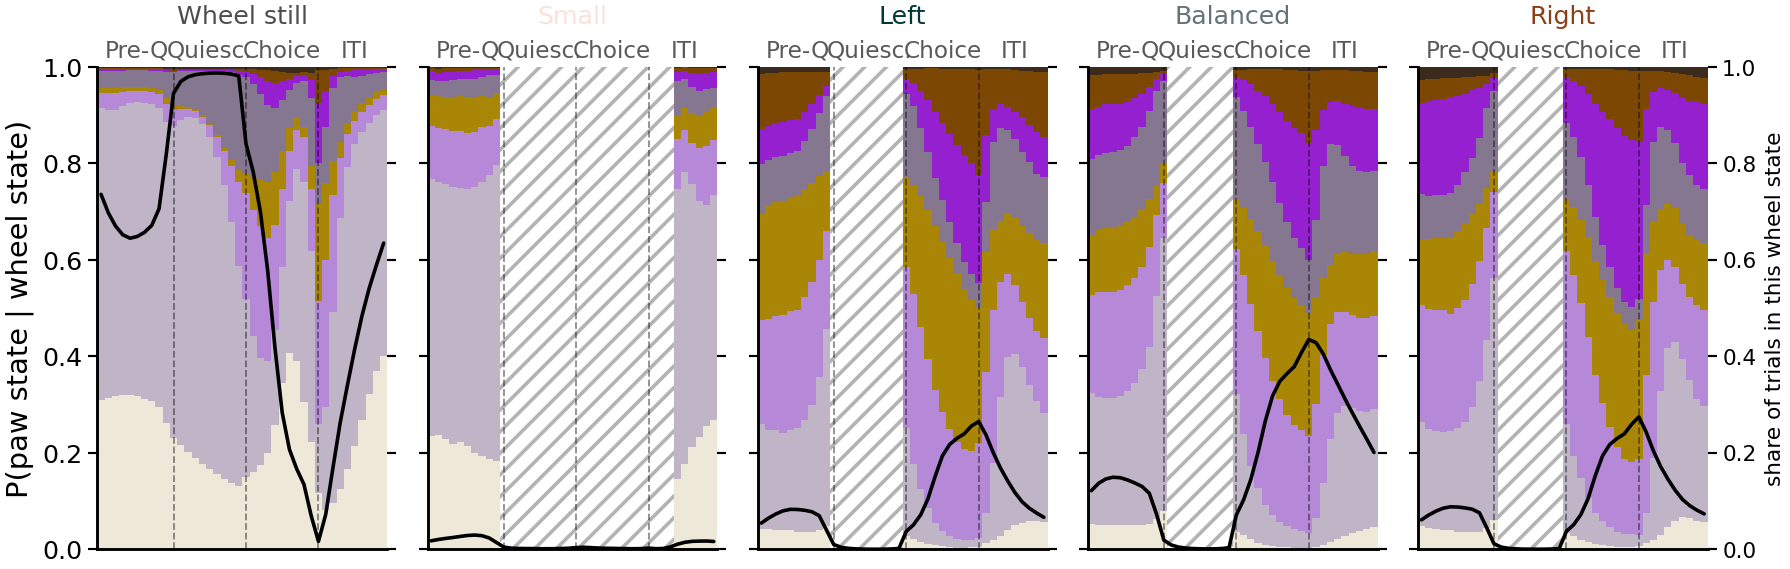

In [9]:
full = pd.read_parquet(SYL, columns=['sample', 'broader_label', 'binned_sequence', 'wheel_binned_sequence'])
EP = ps.EPOCH_NAMES
piv = full.pivot(index='sample', columns='broader_label', values=['binned_sequence', 'wheel_binned_sequence']).dropna()
codes_all = np.vstack([np.hstack(r) for r in piv[[('binned_sequence', e) for e in EP]].to_numpy()]).astype(float)
wheel_all = np.vstack([np.hstack(r) for r in piv[[('wheel_binned_sequence', e) for e in EP]].to_numpy()]).astype(float)
paw_all, _, _ = ps.decode_syllables(ps.paw_codes(codes_all), ps.N_PAW_STATES)
COND = {'Wheel still': [0], 'Small': [1], 'Left': [2, 3], 'Balanced': [4, 5], 'Right': [6, 7]}
NB = paw_all.shape[1]
comp, support = {}, {}
for name, states in COND.items():
    m_ = np.isin(wheel_all, states) & np.isfinite(paw_all)
    support[name] = m_.mean(0)
    comp[name] = np.stack([((paw_all == k) & m_).sum(0) / np.maximum(m_.sum(0), 1) for k in range(ps.N_PAW_STATES)])
print(f'{len(paw_all):,} trials;', {k: f'{v.mean():.1%}' for k, v in support.items()}, '(mean share of bins)')
ORDER_P = list(ps.PAW_VIGOR_ORDER)
fig, axs = plt.subplots(1, len(COND), figsize=(7.09, 2.4), sharey=True)
x = np.arange(NB)
for ax, (name, states) in zip(axs, COND.items()):
    bottom = np.zeros(NB)
    for k in ORDER_P:
        ax.bar(x, comp[name][k], bottom=bottom, width=1.0, color=ps.PAW_STATE_COLORS[k], lw=0); bottom += comp[name][k]
    low = support[name] < 0.01
    ax.bar(x[low], np.ones(low.sum()), width=1.0, color='white', hatch='////', edgecolor='0.7', lw=0)
    ax2 = ax.twinx(); ax2.plot(x, support[name], color='k', lw=1); ax2.set_ylim(0, 1)
    ax2.tick_params(labelright=(name == 'Right'), labelsize=6)
    if name == 'Right': ax2.set_ylabel('share of trials in this wheel state', fontsize=6)
    ps.epoch_lines(ax, NB, label=True, names=ps.EPOCH_SHORT)
    ax.set(xlim=(-0.5, NB - 0.5), ylim=(0, 1), xticks=[]); ax.set_title(f'{name}', fontsize=7, pad=12,
                                                                        color=WHEEL_COLORS[states[-1]] if states[0] else '0.3')
axs[0].set_ylabel('P(paw state | wheel state)')
plt.tight_layout()

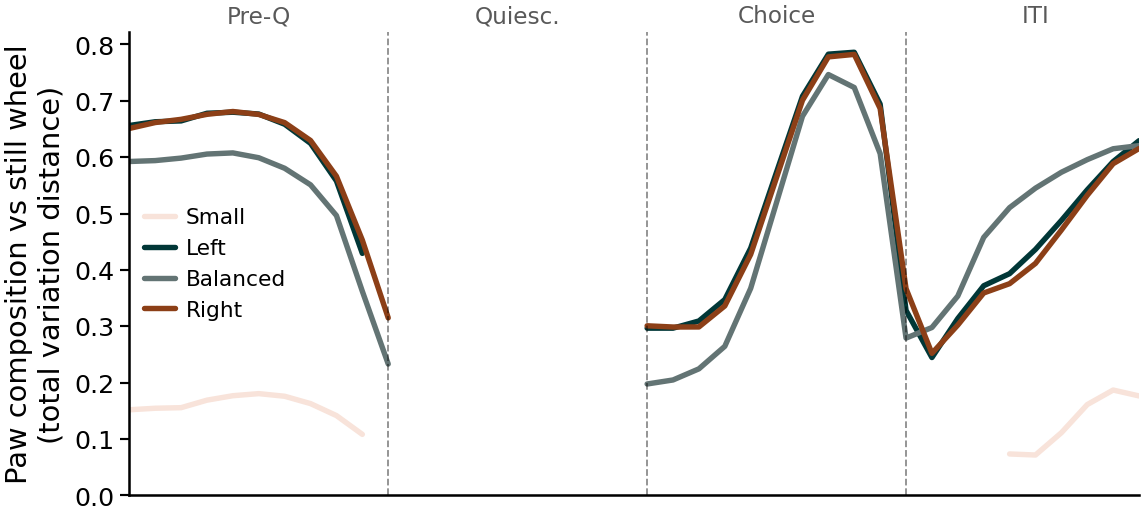

In [10]:
# the same, summarised: how different is the paw composition between wheel conditions, bin by bin?
# total-variation distance of each condition's paw composition from the still-wheel one (0 = identical, 1 = disjoint)
fig, ax = plt.subplots(figsize=(4.6, 2.2))
for name, states in COND.items():
    if name == 'Wheel still': continue
    tv = 0.5 * np.abs(comp[name] - comp['Wheel still']).sum(0)
    tv[support[name] < 0.01] = np.nan
    ax.plot(x, tv, color=WHEEL_COLORS[states[-1]], lw=1.5, label=name)
ps.epoch_lines(ax, NB, label=True, names=ps.EPOCH_SHORT)
ax.set(xlim=(0, NB - 1), ylim=(0, None), xticks=[], ylabel='Paw composition vs still wheel\n(total variation distance)')
ax.legend(frameon=False, fontsize=6); plt.tight_layout()

## G: textures v2 — wheel as horizontal stripes, whisking as grey '\\' lines, licking as dark grey dots

One texture renderer (`texture_rgb`) for both plots, working on pixel-level arrays of paw, wheel, whisking and licking:
- paw = base colour; wheel (while moving) = **horizontal** stripes in the wheel colour; whisking = thin grey '\\' lines; licking = dark grey dots.

**Trial stacks**: each trial upsampled to `SUB_G` pixel rows, a white line between trials.
**Time-warped composition** (the original all-trials panel, as a sorted image): for every bin (4 epochs × 10), the trials are sorted by (paw state in vigor order, wheel state, whisking, licking) and resampled to `N_ROWS` rows, so each column is that bin's joint composition and the image reads like the original stacked composition, textures included.

In [11]:
SUB_G, P_STRIPE, P_WHISK, DOT_G = 12, 4, 6, 4
WHISK_GREY_G, LICK_DOT_G = np.array(to_rgb('#505050')), np.array(to_rgb('#141414'))
def texture_rgb(pr, wr, whr, lr):
    """pixel arrays (rows x cols) of paw, wheel, whisk, lick -> RGB image with the textures."""
    yy, xx = np.mgrid[:pr.shape[0], :pr.shape[1]]
    img = np.where(np.isfinite(pr)[..., None], PAW_RGB[np.nan_to_num(pr).astype(int)], 1.0)
    wheel_on = (np.nan_to_num(wr) > 0) & ((yy // (P_STRIPE // 2)) % 2 == 1)          # horizontal stripes
    img = np.where(wheel_on[..., None], WHEEL_RGB[np.nan_to_num(wr).astype(int)], img)
    whisk_on = (whr == 1) & (((xx - yy) % P_WHISK) <= 1) & ~wheel_on                   # thin '\\' lines
    img = np.where(whisk_on[..., None], WHISK_GREY_G, img)
    lick_on = (lr == 1) & (xx % DOT_G >= 1) & (xx % DOT_G <= 2) & (yy % DOT_G >= 1) & (yy % DOT_G <= 2)   # 2x2 dots
    return np.where(lick_on[..., None], LICK_DOT_G, img)

def draw_G_stack(ax, s, m, title=True):
    paw, W, tr = stack(s, m); wh, li = stack.whisk_lick
    up = lambda a: np.repeat(a, SUB_G, axis=0)
    img = texture_rgb(up(paw), up(W), up(wh), up(li))
    img[np.arange(img.shape[0]) % SUB_G == SUB_G - 1] = 1.0
    ax.imshow(img, aspect='auto', interpolation='nearest', extent=[-T_BEFORE, T_AFTER, len(tr) - 0.5, -0.5])
    ax.axvline(0, color='0.1', lw=0.5, ls=(0, (3, 2)))
    for i, (_, row) in enumerate(tr.iterrows()):
        a = row[ALIGN]
        def mark(t, c):
            if np.isfinite(t) and -T_BEFORE <= t - a <= T_AFTER:
                ax.plot([t - a] * 2, [i - 0.45, i + 0.4], color=c, lw=0.8, solid_capstyle='butt')
        mark(row.get('stimOn_times', np.nan), EVENTS['stim on'])
        fb = row.get('feedbackType', np.nan)
        if np.isfinite(fb): mark(row.get('feedback_times', np.nan), FEEDBACK.get(int(fb), '0.4'))
    ax.set_yticks([0, len(tr) - 1]); ax.set_yticklabels([1, len(tr)])
    if title: ax.set_title(m, fontsize=7)

N_ROWS, COL_UP = 240, 10
PAW_RANK = {k: i for i, k in enumerate(ps.PAW_VIGOR_ORDER)}
def composition_image(codes, wheel):
    """trials x 40 time-warped codes / wheel states -> per-bin sorted, resampled pixel arrays (N_ROWS x 40 * COL_UP)."""
    paw, wh, li = ps.decode_syllables(ps.paw_codes(codes), ps.N_PAW_STATES)
    out = {k: np.full((N_ROWS, codes.shape[1]), np.nan) for k in ('paw', 'wheel', 'whisk', 'lick')}
    for b in range(codes.shape[1]):
        ok = np.isfinite(paw[:, b]) & np.isfinite(wheel[:, b])
        p, w, h, l = paw[ok, b], wheel[ok, b], wh[ok, b], li[ok, b]
        key = np.lexsort((l, h, w, np.vectorize(PAW_RANK.get)(p.astype(int))))   # paw (vigor) first, then wheel, whisk, lick
        pick = key[np.linspace(0, len(key) - 1, N_ROWS).round().astype(int)] if len(key) else []
        for k, v in (('paw', p), ('wheel', w), ('whisk', h), ('lick', l)):
            if len(key): out[k][:, b] = v[pick]
    return {k: np.repeat(v, COL_UP, axis=1) for k, v in out.items()}

def draw_G_comp(ax, codes, wheel, title):
    A = composition_image(codes, wheel)
    ax.imshow(texture_rgb(A['paw'], A['wheel'], A['whisk'], A['lick']), aspect='auto', interpolation='nearest',
              extent=[0, codes.shape[1], 1, 0])
    for e in range(1, 4): ax.axvline(e * 10, color='white', lw=1.0)
    ax.set_xticks([5, 15, 25, 35]); ax.set_xticklabels(ps.EPOCH_SHORT, rotation=45, ha='right', fontsize=6)
    ax.set_yticks([0, 1]); ax.set_yticklabels([0, 1]); ax.set_title(title, fontsize=7)

# per-session time-warped codes for the example sessions, from the same syllable file
piv_s = full.assign(session=full['sample'].str[:36])
def session_codes(sess):
    q = piv[piv.index.str[:36] == sess]
    c = np.vstack([np.hstack(r) for r in q[[('binned_sequence', e) for e in EP]].to_numpy()]).astype(float)
    w = np.vstack([np.hstack(r) for r in q[[('wheel_binned_sequence', e) for e in EP]].to_numpy()]).astype(float)
    return c, w

Text(0.5, 0.51, 'Time from go cue (s)')

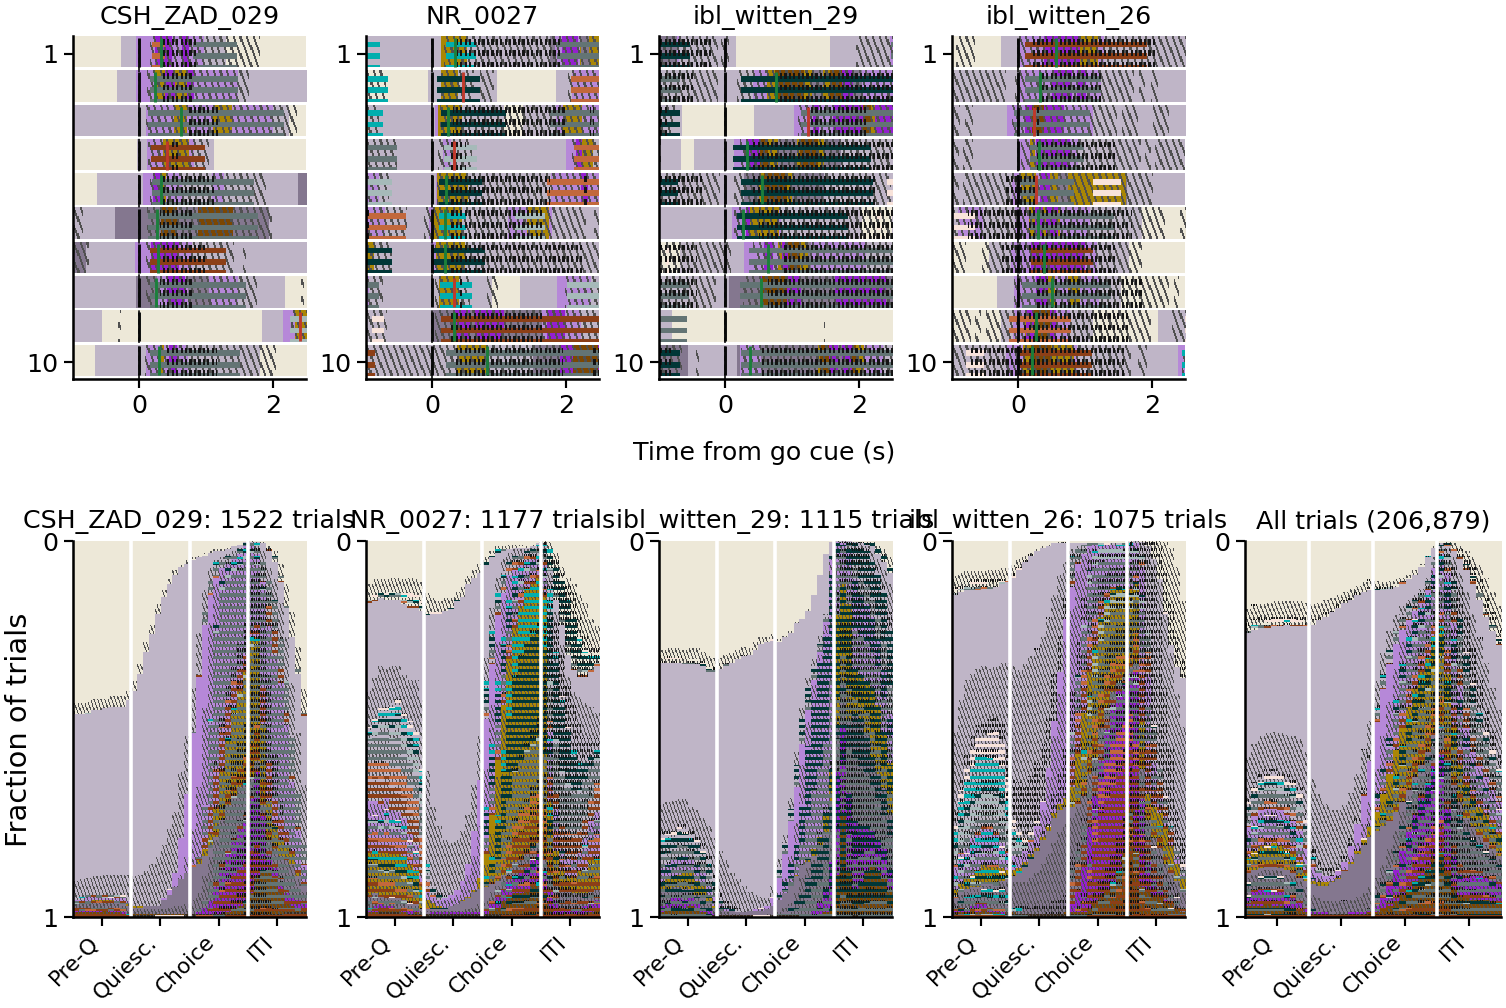

In [12]:
fig = plt.figure(figsize=(7.09, 4.4))
g = fig.add_gridspec(2, len(EXAMPLES) + 1, height_ratios=[1, 1.1], width_ratios=[1] * len(EXAMPLES) + [1.1], hspace=0.45, wspace=0.25)
for j, (s, m, n) in enumerate(EXAMPLES):
    draw_G_stack(fig.add_subplot(g[0, j]), s, m)
    c, w = session_codes(s)
    ax = fig.add_subplot(g[1, j]); draw_G_comp(ax, c, w, f'{m}: {len(c)} trials')
    if j == 0: ax.set_ylabel('Fraction of trials')
draw_G_comp(fig.add_subplot(g[1, -1]), ps.paw_codes(codes_all) * 0 + codes_all, wheel_all, f'All trials ({len(codes_all):,})')
fig.text(0.5, 0.51, 'Time from go cue (s)', ha='center', fontsize=7)

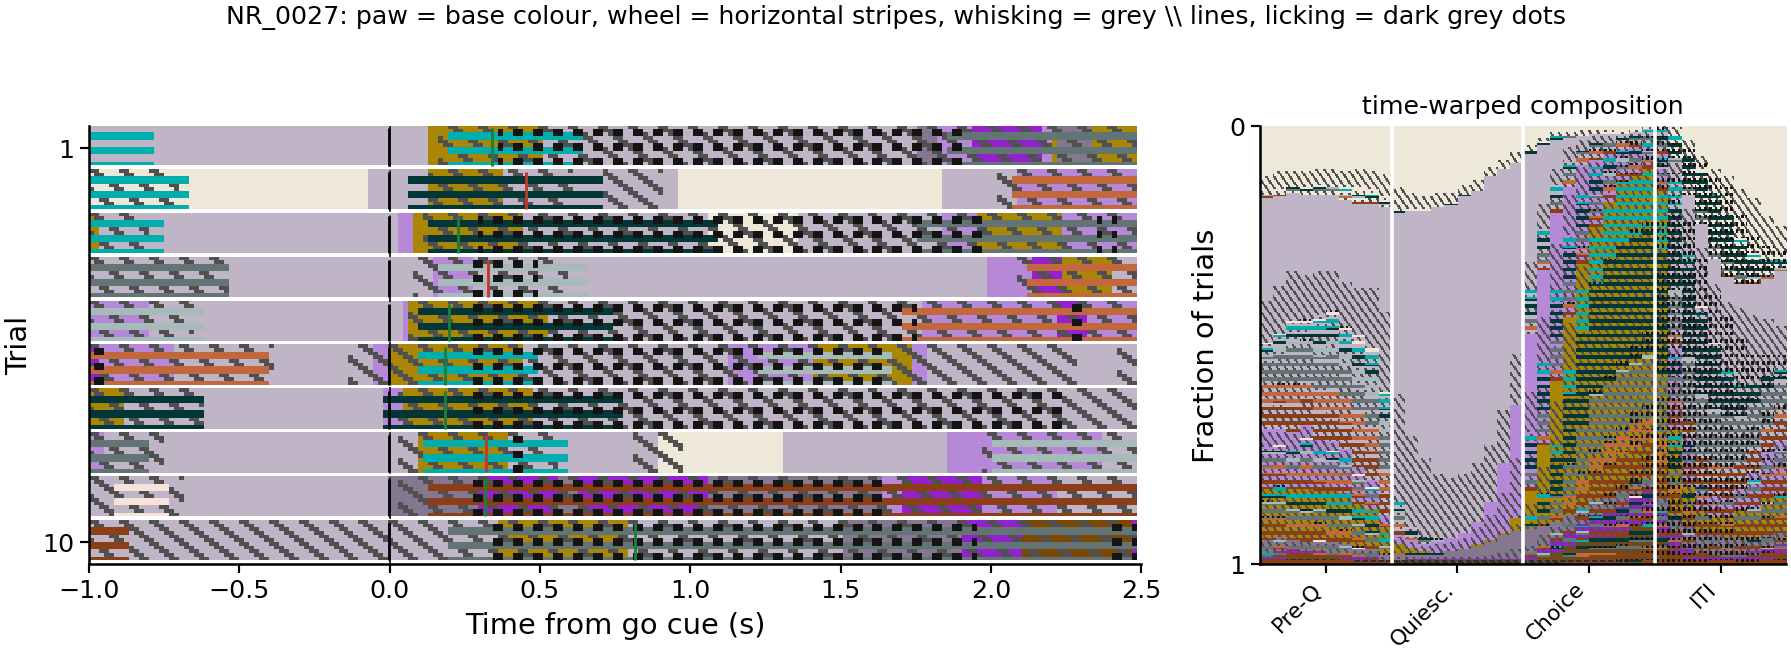

In [13]:
# larger, one session: stack and composition side by side
s, m, n = EXAMPLES[1]
fig, axs = plt.subplots(1, 2, figsize=(7.09, 2.6), gridspec_kw=dict(width_ratios=[2, 1]))
draw_G_stack(axs[0], s, m, title=False); axs[0].set(xlabel='Time from go cue (s)', ylabel='Trial')
c, w = session_codes(s); draw_G_comp(axs[1], c, w, 'time-warped composition'); axs[1].set_ylabel('Fraction of trials')
fig.suptitle(f'{m}: paw = base colour, wheel = horizontal stripes, whisking = grey \\\\ lines, licking = dark grey dots', fontsize=7, y=1.0)
plt.tight_layout()

## Key

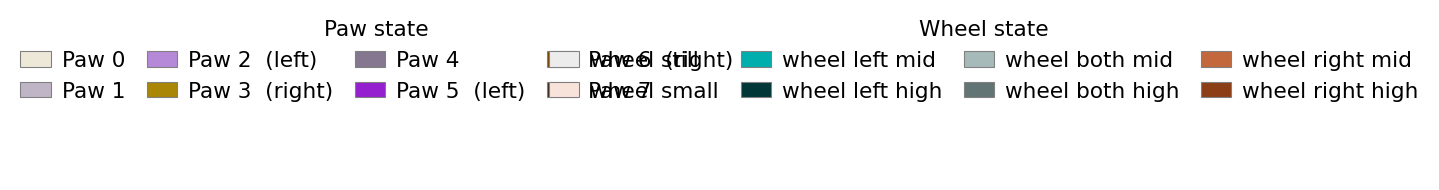

In [14]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(7.09, 0.9)); ax.set_axis_off()
h1 = [Patch(facecolor=c, edgecolor='0.5', lw=0.3, label=ps.paw_label(i)) for i, c in enumerate(ps.PAW_STATE_COLORS)]
h2 = [Patch(facecolor=c, edgecolor='0.5', lw=0.3, label=f'wheel {n}') for n, c in zip(WHEEL_NAMES, WHEEL_COLORS)]
l1 = ax.legend(handles=h1, ncol=4, loc='upper left', frameon=False, fontsize=6, title='Paw state', title_fontsize=6); ax.add_artist(l1)
ax.legend(handles=h2, ncol=4, loc='upper right', frameon=False, fontsize=6, title='Wheel state', title_fontsize=6)